# 딥러닝 2일차 (1) — 퍼셉트론 실습 · 활성화 함수 (계단 · 시그모이드 · ReLU)

수업 필기 `퍼셉트론`(직접 작성) · `퍼셉트론_2`(강의 코드)와 메모 `딥러닝_1일_수정본` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `딥러닝` 교재8 p.21~30 — 퍼셉트론 실습 · 활성화 함수의 개념과 필요성 · 계단 / 시그모이드 / ReLU · 활성화 함수 실습)

- 1일차(퍼셉트론 · 논리 게이트 · XOR · MLP)는 [Day 031 `perceptron_logic_gates.ipynb`](../../2026-10-22/lecture/perceptron_logic_gates.ipynb) 에 있습니다.
- 행렬 곱 · 신경망 층 계산 · 출력층(항등 · 시그모이드 · 소프트맥스)은 [`neural_network_forward.ipynb`](./neural_network_forward.ipynb) 에 이어서 정리했습니다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다. 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. numpy 기초 — 왜 리스트가 아니라 배열인가

퍼셉트론의 가중합 $w_1x_1 + w_2x_2$ 는 **원소끼리 곱한 뒤 더한 것**이다. numpy 배열은 `*` 가 원소끼리 곱셈이라 한 줄로 끝난다.

In [2]:
import numpy as np

x = np.array([0, 1])          # 입력 신호 (x1, x2)
w = np.array([0.5, 0.5])      # 가중치 (w1, w2)
b = -0.7                      # 편향

print("x * w          :", x * w)                  # 원소끼리 곱 → [w1x1, w2x2]
print("np.sum(x * w)  :", np.sum(x * w))          # 가중합 (편향 제외)
print("+ 편향          :", round(np.sum(x * w) + b, 2))      # 입력 신호의 총합 z
print("np.dot(x, w) + b:", round(np.dot(x, w) + b, 2))      # 같은 계산 (내적)

# 파이썬 리스트는 * 로 원소끼리 곱할 수 없다
try:
    [0, 1] * [0.5, 0.5]
except TypeError as e:
    print("리스트 곱셈 에러 :", e)

x * w          : [0.  0.5]
np.sum(x * w)  : 0.5
+ 편향          : -0.2
np.dot(x, w) + b: -0.2
리스트 곱셈 에러 : can't multiply sequence by non-int of type 'list'


> **📝 고친 부분** (`퍼셉트론` 첫 셀)
> - `w = np.array([0, 1])  # 가중치` 와 `x = np.array([0.5, 0.5])` 의 **이름이 서로 바뀌었다** — 0/1 은 입력(x), 0.5 는 가중치(w)
> - `print(output + b)` → 합계 `output2` 를 구해 놓고 **원소별 곱(`output`)에 편향을 더해** `[0.7 1.2]` 처럼 배열이 나왔다 → `np.sum(x * w) + b`
> - 이 셀의 `b = 0.7` 은 AND 의 편향이 아니다(AND 는 **−0.7**)
> - 주석 "파이썬에 리스트는 딥러닝에 연산이 안된다?" → 리스트끼리 `*` 는 `TypeError`. numpy 배열은 원소끼리 곱 · 더하기가 되고 훨씬 빠르다

## 2. 퍼셉트론 실습 — 논리 게이트 (교재 p.21)

퍼셉트론 = **입력 신호의 총합 z** + **활성화 함수**. 1일차에는 `if` 문으로 0/1 을 정했는데, 그 `if` 가 바로 **계단 함수**라는 활성화 함수다.

In [3]:
# 활성화 함수 : 계단 함수 — z >= 0 이면 1, 아니면 0  (값을 '반환'해야 다음 계산에 쓸 수 있다)
def step_function(z):
    return np.where(np.asarray(z) >= 0, 1, 0)

# 퍼셉트론 하나 = 가중합 + 편향 → 계단 함수
def perceptron(x1, x2, w, b):
    x = np.array([x1, x2])
    z = np.sum(x * w) + b          # 입력 신호의 총합
    return int(step_function(z))   # 활성화 함수

def AND(x1, x2):
    return perceptron(x1, x2, w=np.array([0.5, 0.5]), b=-0.7)

def NAND(x1, x2):
    return perceptron(x1, x2, w=np.array([-0.5, -0.5]), b=0.7)   # AND 와 부호 반대

def OR(x1, x2):
    return perceptron(x1, x2, w=np.array([0.5, 0.5]), b=-0.2)    # AND 보다 편향이 덜 음수

def XOR(x1, x2):
    s1 = NAND(x1, x2)     # 은닉층 노드 1
    s2 = OR(x1, x2)       # 은닉층 노드 2
    return AND(s1, s2)    # 출력층

inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]
for name, gate in [('AND', AND), ('NAND', NAND), ('OR', OR), ('XOR', XOR)]:
    print(f"{name:<4} :", {x: gate(*x) for x in inputs})

AND  : {(0, 0): 0, (1, 0): 0, (0, 1): 0, (1, 1): 1}
NAND : {(0, 0): 1, (1, 0): 1, (0, 1): 1, (1, 1): 0}
OR   : {(0, 0): 0, (1, 0): 1, (0, 1): 1, (1, 1): 1}
XOR  : {(0, 0): 0, (1, 0): 1, (0, 1): 1, (1, 1): 0}


> **📝 고친 부분** (`퍼셉트론`)
> - `AND` · `NAND` · `OR` 안에서 `step_func(output)` 을 **호출만 하고 `return` 하지 않아** 결과가 `None` 이었다. 또 `step_func` 는 값을 `print` 만 하고 반환하지 않았다 → `return np.where(...)`
> - `step_func` 를 쓰는 셀이 정의 셀보다 **위**에 있었다 → 노트북을 위에서부터 실행하면 `NameError`. 함수는 쓰기 전에 정의
> - "AND" 라고 출력한 반복문은 `perceptron(x1, x2)` (편향 **+0.7**)를 써서 **입력과 상관없이 전부 1**이 나왔다 — AND 가 아니다
> - 주석 처리된 반복문에서 `s1 = x[0]` — 반복 변수는 `j` 인데 이전 반복문의 `x` 를 써서 **같은 입력만 반복**했다 → `j[0]`
> - `퍼셉트론_2` 주석 오타 `구형` → 구현, `처러` → 처리

## 3. 활성화 함수 — 왜 필요한가 (교재 p.22~23)

**활성화 함수(activation function)** : 입력 신호의 총합 $z = w_1x_1 + w_2x_2 + b$ 를 받아 **다음 뉴런으로 보낼 신호의 모양으로 바꾸는 함수**.

가중합은 **직선(선형)** 이다. 활성화 함수 없이 층만 쌓으면?

$$y = w_2(w_1x + b_1) + b_2 = (w_2w_1)\,x + (w_2b_1 + b_2) = Wx + B$$

**수백 층을 쌓아도 결국 직선 하나** — 층을 쌓은 의미가 없다. 활성화 함수가 직선을 **꺾고 구부려** 곡선 경계를 만든다.

In [4]:
rng = np.random.default_rng(0)
x = np.linspace(-3, 3, 7).reshape(-1, 1)           # 입력 7개 (1차원)

W1, b1 = rng.normal(size=(1, 4)), rng.normal(size=4)   # 1 → 4 (은닉층)
W2, b2 = rng.normal(size=(4, 1)), rng.normal(size=1)   # 4 → 1 (출력층)

# 활성화 함수 없이 2층
y_linear = (x @ W1 + b1) @ W2 + b2
# 하나의 직선으로 합쳐 보기 : W = W1·W2, B = b1·W2 + b2
W, B = W1 @ W2, b1 @ W2 + b2
print("2층 (활성화 X) :", y_linear.ravel().round(3))
print("직선 1개 Wx + B:", (x @ W + B).ravel().round(3), " ← 완전히 같다")

# 은닉층에 ReLU 를 넣으면 더 이상 직선 하나로 쓸 수 없다
y_relu = np.maximum(0, x @ W1 + b1) @ W2 + b2
print("2층 (ReLU)     :", y_relu.ravel().round(3))
print("이웃한 점 사이 기울기 — 활성화 X :", np.diff(y_linear.ravel()).round(3))
print("이웃한 점 사이 기울기 — ReLU     :", np.diff(y_relu.ravel()).round(3), " ← 구간마다 꺾인다")

2층 (활성화 X) : [-2.231 -2.547 -2.863 -3.179 -3.495 -3.812 -4.128]
직선 1개 Wx + B: [-2.231 -2.547 -2.863 -3.179 -3.495 -3.812 -4.128]  ← 완전히 같다
2층 (ReLU)     : [-3.258 -3.101 -3.329 -3.556 -3.784 -4.012 -4.283]
이웃한 점 사이 기울기 — 활성화 X : [-0.316 -0.316 -0.316 -0.316 -0.316 -0.316]
이웃한 점 사이 기울기 — ReLU     : [ 0.157 -0.228 -0.228 -0.228 -0.228 -0.272]  ← 구간마다 꺾인다


![ReLU 로 곡선 만들기](./images/anim_01_relu_bend.gif)

🎬 은닉층 ReLU 뉴런을 1개 → 12개로 늘리며 곡선(사인파)을 따라가게 했다. 뉴런 하나 = **꺾인 자** 하나. 꺾인 자를 여러 개 더하면 곡선에 가까워진다. 활성화 함수를 빼면(회색 점선) 뉴런을 아무리 늘려도 **직선 하나**다.

## 4. 계단 · 시그모이드 · ReLU (교재 p.24~29)

| 함수 | 식 | 출력 범위 | 기울기(미분) | 쓰임 |
|---|---|---|---|---|
| **계단** | $z \ge 0$ → 1, 아니면 0 | 0 또는 1 | **0** (0 에서는 정의 안 됨) | 1950년대 퍼셉트론 |
| **시그모이드** | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | 0 ~ 1 (확률) | $\sigma(1-\sigma)$, 최대 **0.25** | 이진 분류 출력층 |
| **ReLU** | $\max(0, z)$ | 0 ~ ∞ | $z > 0$ 이면 **1**, $z < 0$ 이면 0 | **은닉층의 표준** |

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))          # np.exp(-z) = e 의 -z 제곱 (지수 함수)

def relu(z):
    return np.maximum(0, z)              # 0 과 z 중 큰 값 → 음수는 0

z = np.array([-5.0, -2.0, -0.5, 0.0, 0.5, 2.0, 5.0])
print("z          :", z)
print("계단 함수  :", step_function(z))
print("시그모이드 :", sigmoid(z).round(4))
print("ReLU       :", relu(z))

z          : [-5.  -2.  -0.5  0.   0.5  2.   5. ]
계단 함수  : [0 0 0 1 1 1 1]
시그모이드 : [0.0067 0.1192 0.3775 0.5    0.6225 0.8808 0.9933]
ReLU       : [0.  0.  0.  0.  0.5 2.  5. ]


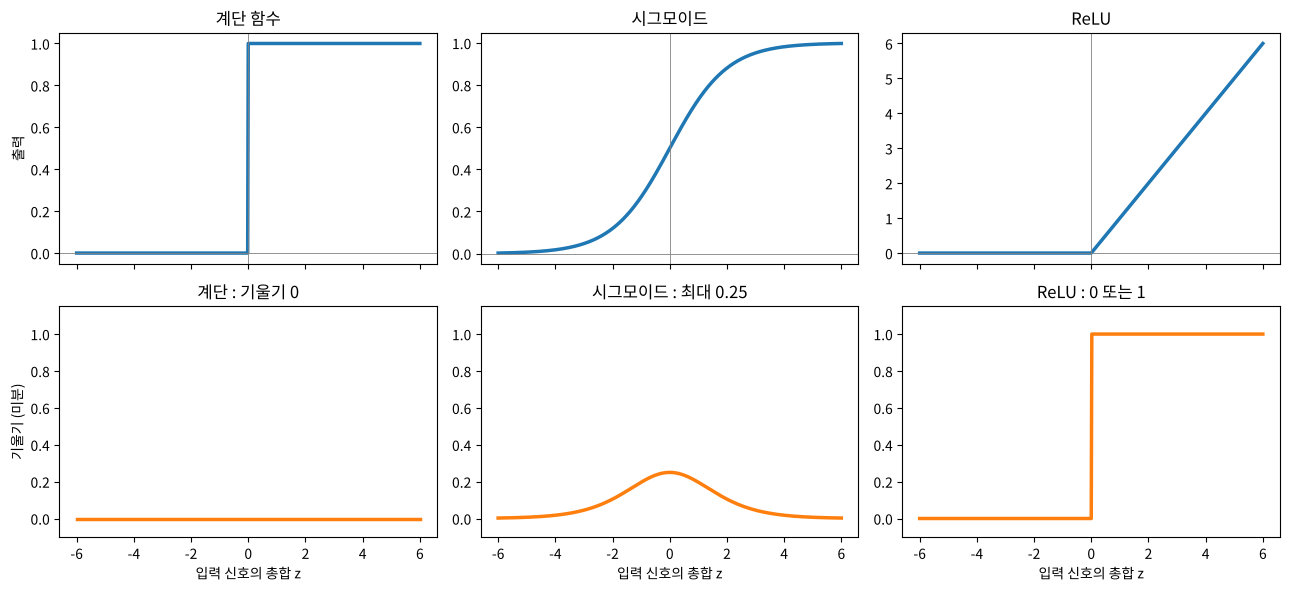

In [6]:
zs = np.linspace(-6, 6, 601)
funcs = [('계단 함수', step_function(zs)), ('시그모이드', sigmoid(zs)), ('ReLU', relu(zs))]
grads = [('계단 : 기울기 0', np.zeros_like(zs)),
         ('시그모이드 : 최대 0.25', sigmoid(zs) * (1 - sigmoid(zs))),
         ('ReLU : 0 또는 1', (zs > 0).astype(float))]

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, (name, y) in zip(axes[0], funcs):
    ax.plot(zs, y, lw=2.5); ax.set_title(name); ax.axhline(0, color='gray', lw=0.6); ax.axvline(0, color='gray', lw=0.6)
for ax, (name, g) in zip(axes[1], grads):
    ax.plot(zs, g, lw=2.5, color='tab:orange'); ax.set_title(name); ax.set_ylim(-0.1, 1.15)
    ax.set_xlabel('입력 신호의 총합 z')
axes[0, 0].set_ylabel('출력'); axes[1, 0].set_ylabel('기울기 (미분)')
plt.tight_layout()
plt.show()

![활성화 함수와 기울기 애니메이션](./images/anim_02_activation_slope.gif)

🎬 z 를 −6 → 6 으로 움직이며 각 함수 위의 점과 **접선(기울기)** 을 그렸다.
- **계단** : 어디서나 평평 → 기울기 0. "가중치를 조금 바꾸면 오차가 얼마나 줄까?" 를 알 수 없어서 **경사하강법으로 학습할 수 없다**.
- **시그모이드** : 부드러워 미분은 되지만, z 가 크거나 작으면 곡선이 평평해져(**포화**) 기울기가 0 에 가깝다. 가운데서도 최대 0.25.
- **ReLU** : 양수 구간은 기울기가 항상 **1** — 계산도 비교 한 번이라 빠르다.

In [7]:
# 시그모이드 출력 = '1(양성)일 확률' → 0(음성)일 확률은 1 - p
p = sigmoid(0.85)
print(f"z = 0.85 → 클래스 1 일 확률 {p:.3f}, 클래스 0 일 확률 {1 - p:.3f}")

# 기울기 소실 : 층마다 기울기가 곱해진다 (역전파)
for n in [1, 5, 10, 20]:
    print(f"층 {n:>2}개 — 시그모이드 최대 기울기 0.25^{n} = {0.25 ** n:.2e}   |   ReLU 1^{n} = 1")

z = 0.85 → 클래스 1 일 확률 0.701, 클래스 0 일 확률 0.299
층  1개 — 시그모이드 최대 기울기 0.25^1 = 2.50e-01   |   ReLU 1^1 = 1
층  5개 — 시그모이드 최대 기울기 0.25^5 = 9.77e-04   |   ReLU 1^5 = 1
층 10개 — 시그모이드 최대 기울기 0.25^10 = 9.54e-07   |   ReLU 1^10 = 1
층 20개 — 시그모이드 최대 기울기 0.25^20 = 9.09e-13   |   ReLU 1^20 = 1


![기울기 소실 애니메이션](./images/anim_03_vanishing_gradient.gif)

🎬 출력층에서 계산한 오차의 기울기를 입력층 쪽으로 한 층씩 전달할 때(역전파), 층을 지날 때마다 **활성화 함수의 기울기가 곱해진다**. 시그모이드는 층마다 최대 0.25 배 → 10층이면 **0.000001 배**로 줄어 앞쪽 층은 거의 학습되지 않는다(**기울기 소실**). ReLU 는 양수 구간에서 1 배라 그대로 전달된다.

> **📝 고친 부분** (`퍼셉트론` · 교재)
> - 함수 이름 `sigmold` → **sigmoid**, `ReLu` → **ReLU**(Rectified Linear Unit), 변수 `perceptron_ouput` → output, 주석 `퍼셉트로노` · `은닉충` 오타
> - 시그모이드 셀은 `perceptron()`(편향 **+0.7**)의 출력을 넣어서 4개 입력 모두 0.5 이상 — AND 와는 무관한 값이다. 시그모이드 자체는 맞게 구현됐다
> - 교재 p.24 계단 함수 "0을 **넘으면** 1, 0 **이하**이면 0" 과 1일차 정의(z **≥** 0 이면 1)가 0 에서 다르다 — 이 노트는 1일차 · 수업 코드와 같은 **z ≥ 0 → 1** 로 통일
> - 교재 p.25 "기울기(w)와 **편차**(b)" → 가중치(w)와 **편향**(b)
> - 교재 p.29 ReLU "경사 소실 문제의 **완벽한** 해결" → 양수 구간에서만이다. 입력이 계속 음수인 뉴런은 기울기 0 이 되어 영원히 꺼지는 **dying ReLU** 문제가 있어 Leaky ReLU · GELU 같은 변형을 쓰기도 한다

## 5. 정리

| | 계단 | 시그모이드 | ReLU |
|---|---|---|---|
| 출력 | 0 / 1 | 0 ~ 1 확률 | 0 또는 그대로 |
| 학습(미분) | ✗ (기울기 0) | ○ (깊으면 기울기 소실) | ○ (양수 구간 기울기 1) |
| 어디에 | 퍼셉트론 · 논리 게이트 | **이진 분류 출력층** | **은닉층** |

- 활성화 함수가 없으면 층을 아무리 쌓아도 **직선 하나**와 같다 → 활성화 함수가 신경망을 "깊게" 만든다.
- 다음 노트 : 층 전체를 **행렬 곱 한 번**으로 계산하고, 출력층에서 문제 유형(회귀 · 이진 · 다중 분류)에 맞는 함수를 고른다.